# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import S1S2WaterDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.models import DeepLabV3_13_bands
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import numpy as np
import csv 

## Sentinel-1 images

### Visualize images and masks

Total number of patches: 60


2025-03-27 11:46:09,295 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


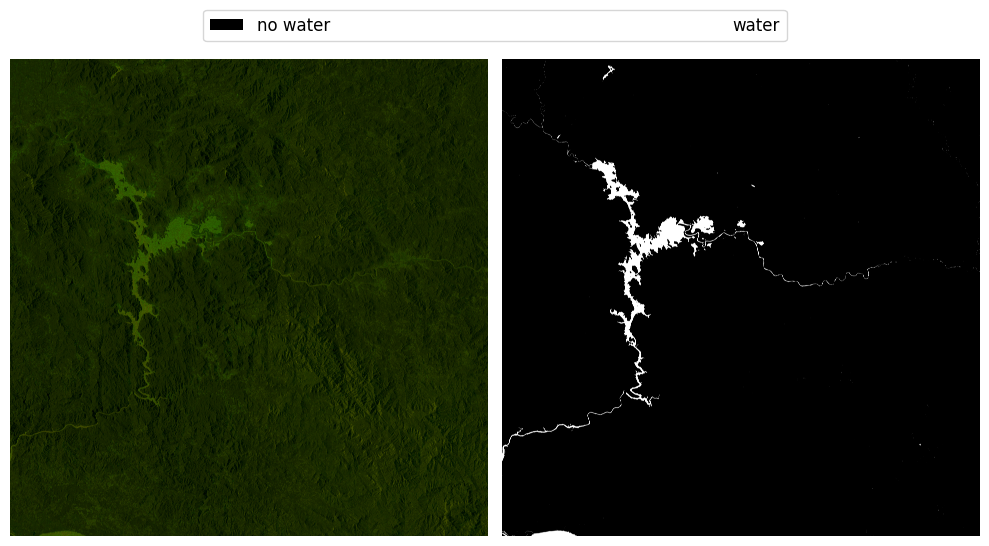

2025-03-27 11:46:42,642 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


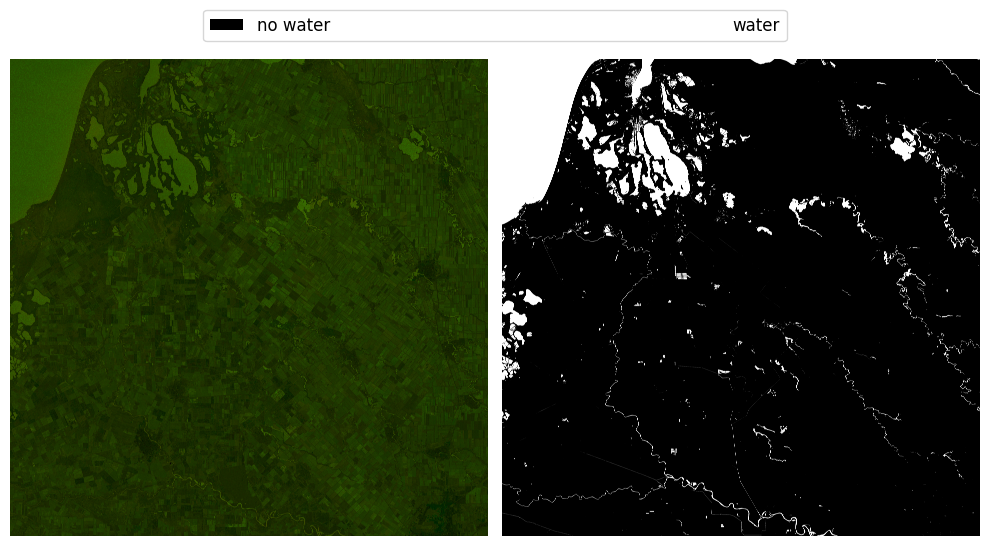

2025-03-27 11:47:28,857 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


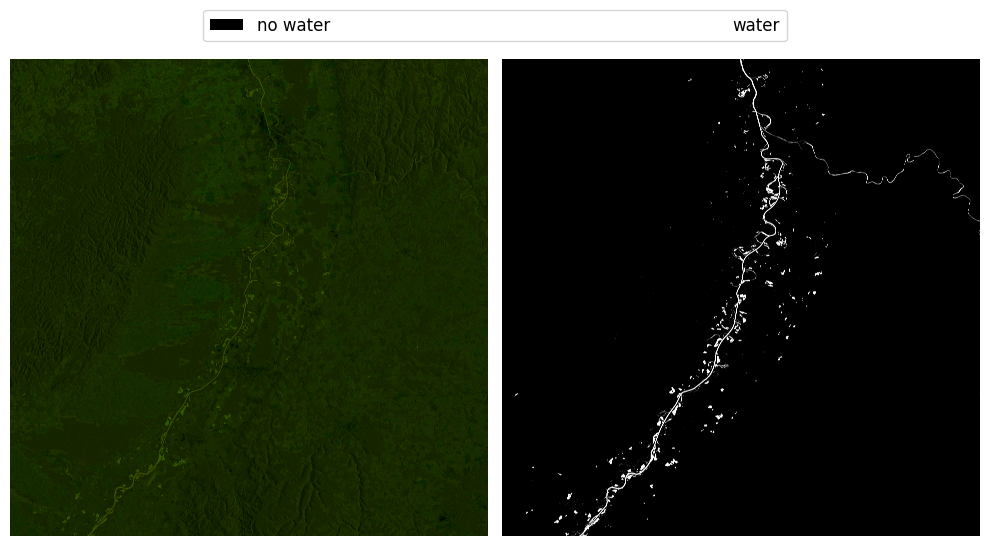

In [ ]:
dataset_config = {
    "data_dir": "./data/S1S2-Water/S1"
}
dataset = S1S2WaterDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(50);

In [25]:
dataset.data_distribution_table()

,Number of pixels
no water,9.293411e+09
water,1.216788e+09


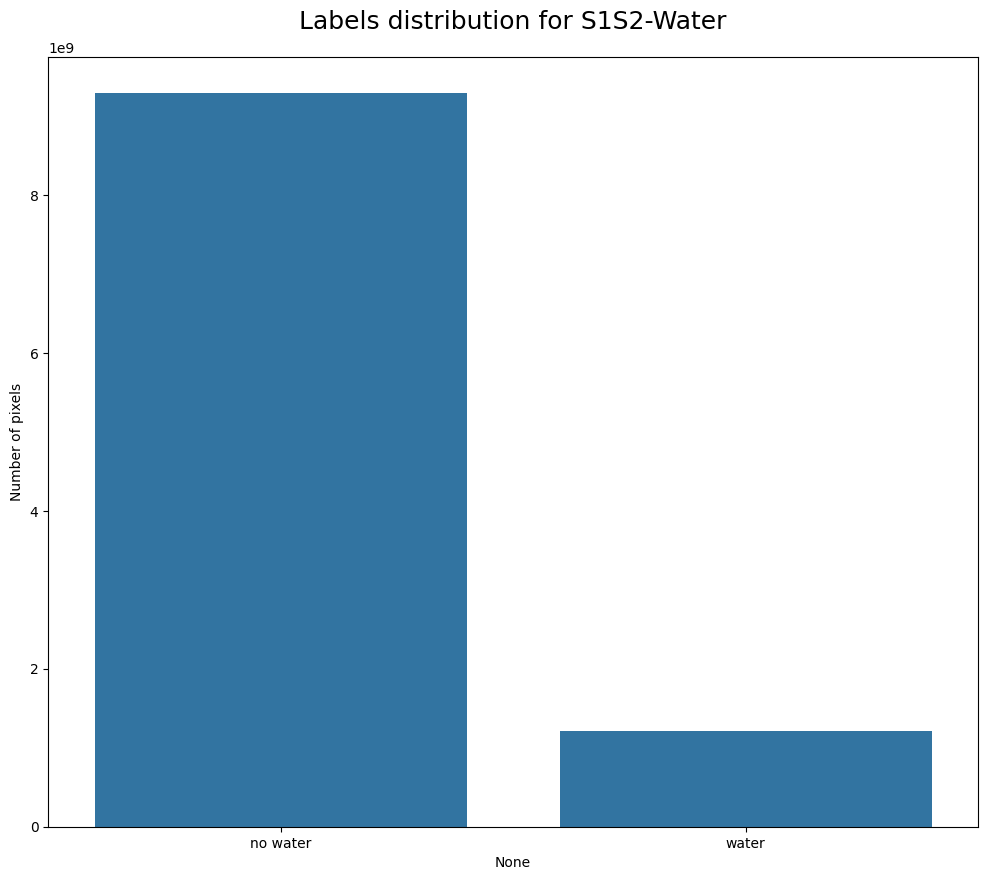

In [26]:
dataset.data_distribution_barchart();

### Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 0,
    "data_dir": "./data/S1S2-Water/S1",
    "csv_file": "./data/S1S2-Water/S1/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = S1S2WaterDataset(train_dataset_config)
len(train_dataset)

48

### Create the model

In [ ]:
epochs = 10
model_directory = "./data/S1S2-Water/S1"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

### Start the training

In [63]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-27 11:52:15,872 INFO Starting training.
training: 100%|██████████| 6/6 [04:05<00:00, 40.87s/it]
2025-03-27 11:56:21,203 INFO epoch: 1, time: 246, loss:  0.49288
testing on train set: 100%|██████████| 6/6 [04:04<00:00, 40.75s/it]
2025-03-27 12:00:27,669 INFO IOU:0.21201498794427365, IOU mean:0.2028491310173296, IOU per Class:[0.32431263 0.08138564]
training: 100%|██████████| 6/6 [04:02<00:00, 40.45s/it]
2025-03-27 12:04:30,394 INFO epoch: 2, time: 243, loss:  0.45996
testing on train set: 100%|██████████| 6/6 [04:02<00:00, 40.40s/it]
2025-03-27 12:08:32,802 INFO IOU:0.41550355947058787, IOU mean:0.31015350566251465, IOU per Class:[0.53043826 0.08986875]
training: 100%|██████████| 6/6 [04:04<00:00, 40.83s/it]
2025-03-27 12:12:37,790 INFO epoch: 3, time: 245, loss:  0.43150
testing on train set: 100%|██████████| 6/6 [04:03<00:00, 40.56s/it]
2025-03-27 12:16:41,146 INFO IOU:0.37596714647668494, IOU mean:0.30227326658336867, IOU per Class:[0.48387338 0.12067315]
training: 100%|█████

### Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/S1S2-Water/S1",
    "csv_file": "./data/S1S2-Water/S1/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = S1S2WaterDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/S1S2-Water/S1/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

6


2025-03-27 13:16:10,579 INFO Loading checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S1/checkpoint.pth.tar
2025-03-27 13:16:11,051 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S1/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:27<00:00, 13.85s/it]


[{'IOU': 0.1764835874942467,
  'IOU mean': 0.17190161479343535,
  'IOU per Class': array([0.14795772, 0.19584551])}]

### Predictions

2025-03-27 13:18:10,698 INFO Loading checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S1/checkpoint.pth.tar
2025-03-27 13:18:11,127 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S1/checkpoint.pth.tar at epoch 11
2025-03-27 13:18:17,650 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-27 13:18:24,777 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-27 13:18:31,153 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


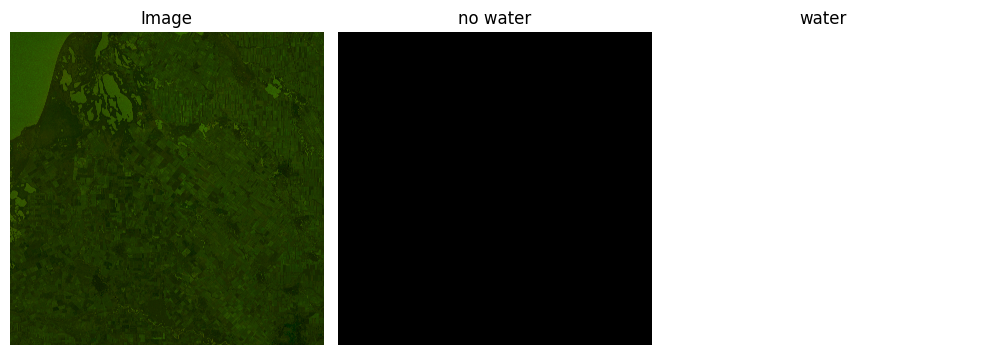

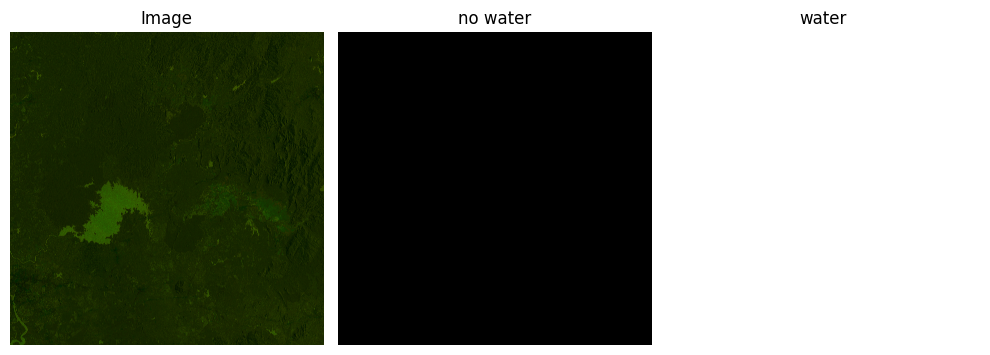

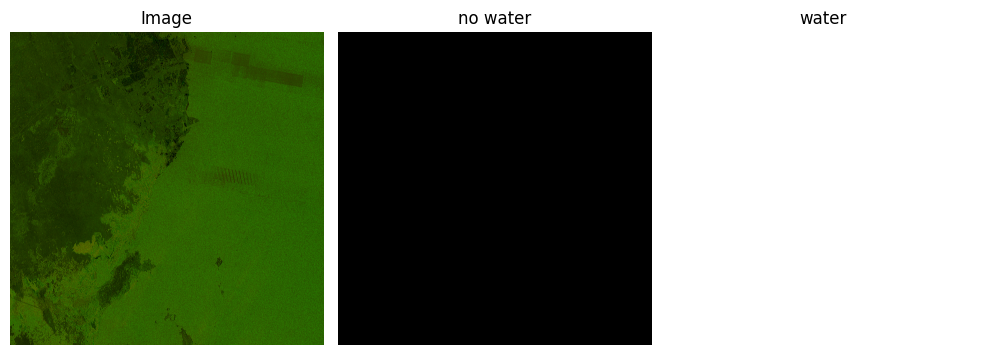

In [ ]:
model_path = "./data/S1S2-Water/S1/checkpoint.pth.tar"
labels = ["no water","water"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "./data/S1S2-Water/S1/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/S1S2-Water/S1/' + test_list[0])
VV = -image[:,:,0]
VH = -image[:,:,1]
VV_VH = VV/VH
image = np.dstack([VV,VH,VV_VH]) / 10000 #initial values are negative DN
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/S1S2-Water/S1/' + test_list[1])
VV = -image[:,:,0]
VH = -image[:,:,1]
VV_VH = VV/VH
image = np.dstack([VV,VH,VV_VH]) / 10000 #initial values are negative DN
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/S1S2-Water/S1/' + test_list[5])
VV = -image[:,:,0]
VH = -image[:,:,1]
VV_VH = VV/VH
image = np.dstack([VV,VH,VV_VH]) / 10000 #initial values are negative DN
fig = model.predict_masks(image, labels, transform)

## Sentinel-2 images

### Visualize images amd masks

Total number of patches: 61


2025-03-27 13:48:32,143 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


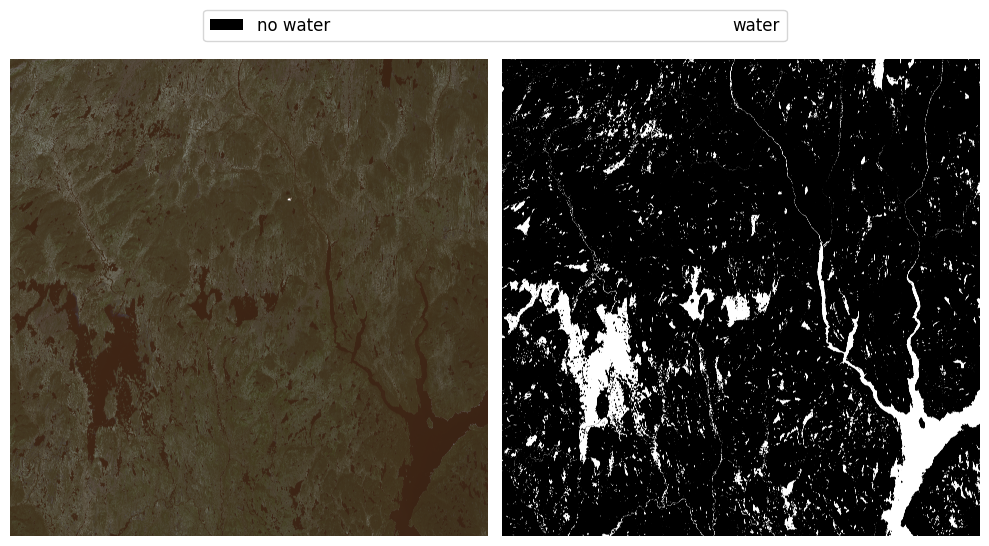

2025-03-27 13:49:02,166 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


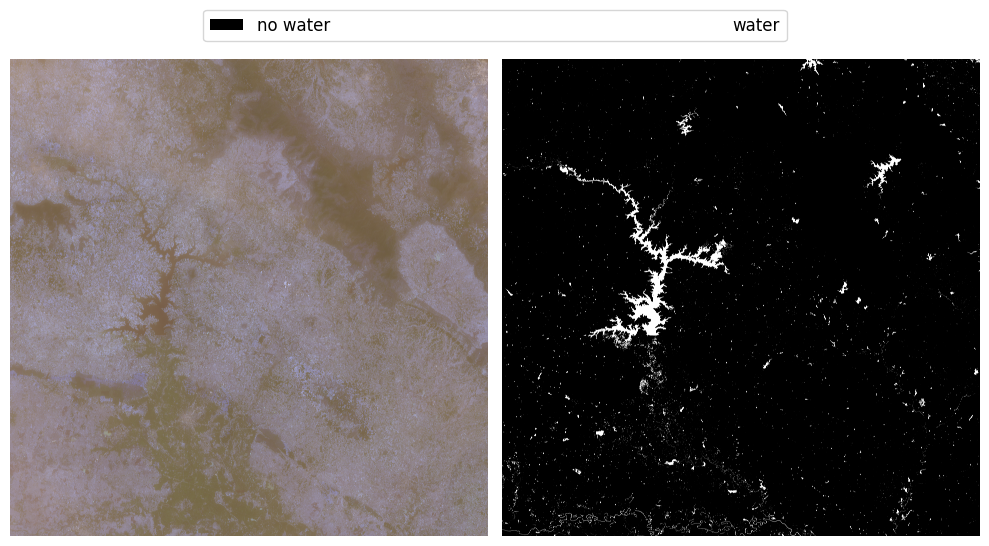

2025-03-27 13:49:32,077 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


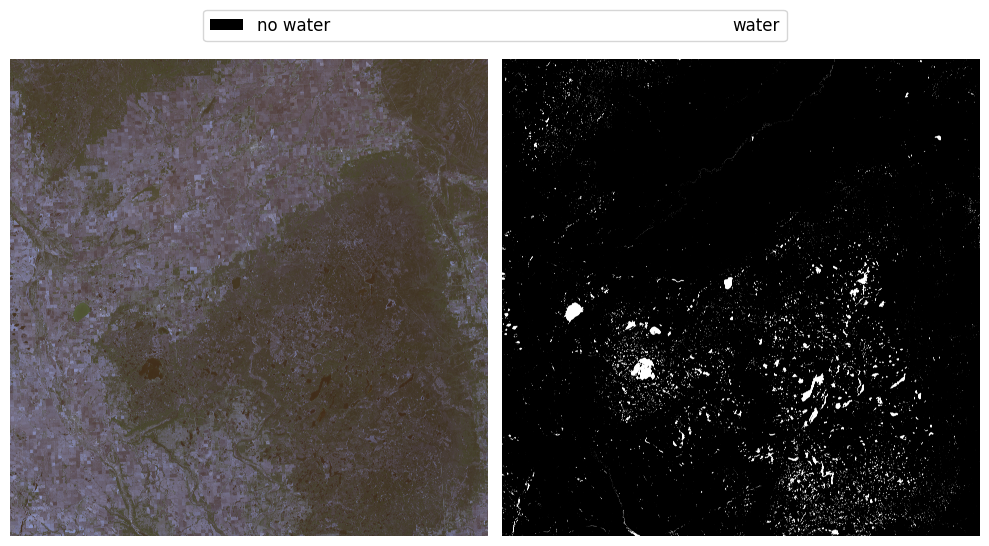

In [ ]:
dataset_config = {
    "data_dir": "./data/S1S2-Water/S2"
}
dataset = S1S2WaterDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(50);

In [89]:
dataset.data_distribution_table()

,Number of pixels
no water,6.441640e+09
water,9.127749e+08


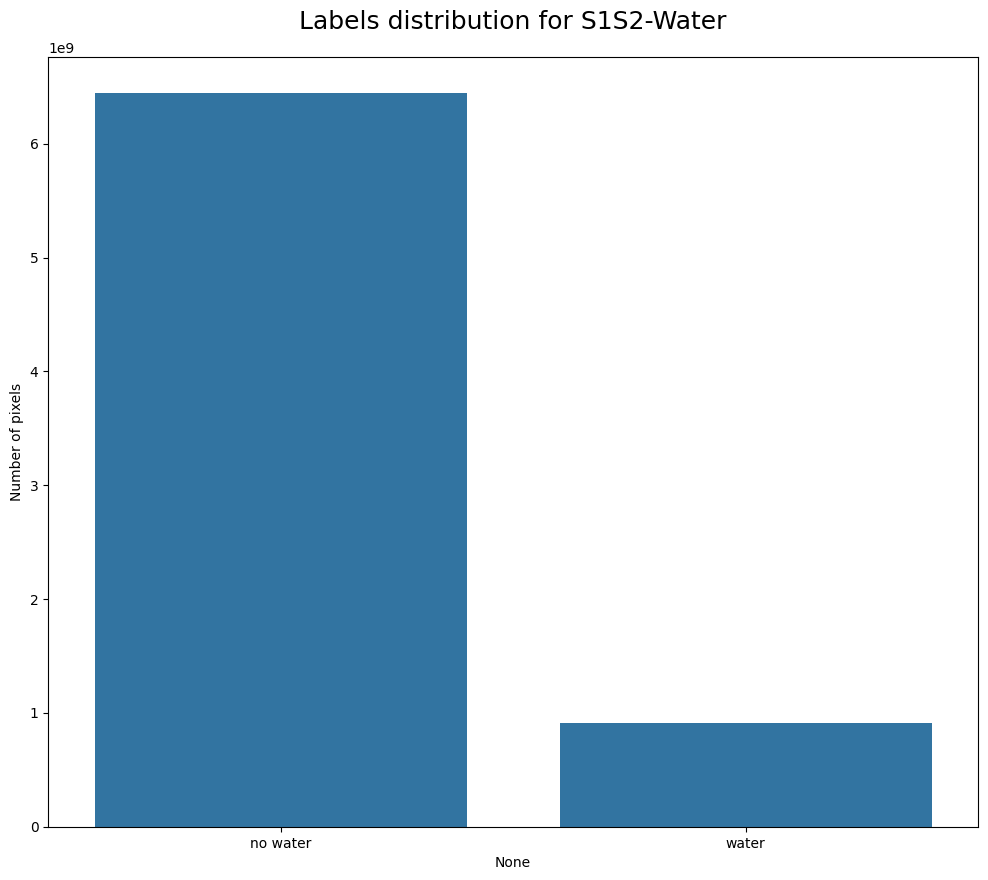

In [90]:
dataset.data_distribution_barchart();

### Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/S1S2-Water/S2",
    "csv_file": "./data/S1S2-Water/S2/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = S1S2WaterDataset(train_dataset_config)
len(train_dataset)

50

### Create the model

In [ ]:
epochs = 10
model_directory = "./data/S1S2-Water/S2"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

### Start the training

In [94]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-27 13:59:43,582 INFO Starting training.
training: 100%|██████████| 13/13 [01:45<00:00,  8.11s/it]
2025-03-27 14:01:29,115 INFO epoch: 1, time: 106, loss:  0.47650
testing on train set: 100%|██████████| 13/13 [01:47<00:00,  8.26s/it]
2025-03-27 14:03:18,053 INFO IOU:0.4237241776471927, IOU mean:0.31130713422989165, IOU per Class:[0.51991107 0.10270319]
training: 100%|██████████| 13/13 [01:34<00:00,  7.30s/it]
2025-03-27 14:04:53,019 INFO epoch: 2, time: 95, loss:  0.44735
testing on train set: 100%|██████████| 13/13 [01:46<00:00,  8.15s/it]
2025-03-27 14:06:39,040 INFO IOU:0.3685000469727901, IOU mean:0.2909498049152995, IOU per Class:[0.47199828 0.10990133]
training: 100%|██████████| 13/13 [01:36<00:00,  7.44s/it]
2025-03-27 14:08:15,800 INFO epoch: 3, time: 96, loss:  0.41858
testing on train set: 100%|██████████| 13/13 [01:41<00:00,  7.82s/it]
2025-03-27 14:09:57,529 INFO IOU:0.416970754838882, IOU mean:0.3269672917093982, IOU per Class:[0.54002659 0.113908  ]
training: 100%|

### Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/S1S2-Water/S2",
    "csv_file": "./data/S1S2-Water/S2/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = S1S2WaterDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/S1S2-Water/S2/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

6


2025-03-27 14:33:58,908 INFO Loading checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S2/checkpoint.pth.tar
2025-03-27 14:33:59,436 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S2/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:27<00:00, 13.94s/it]


[{'IOU': 0.6768608230275929,
  'IOU mean': 0.42062091219491177,
  'IOU per Class': array([0.81464179, 0.02660004])}]

### Predictions

2025-03-27 14:35:24,034 INFO Loading checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S2/checkpoint.pth.tar
2025-03-27 14:35:24,541 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/S1S2-Water/S2/checkpoint.pth.tar at epoch 11
2025-03-27 14:35:30,891 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-27 14:35:36,464 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-27 14:35:42,334 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


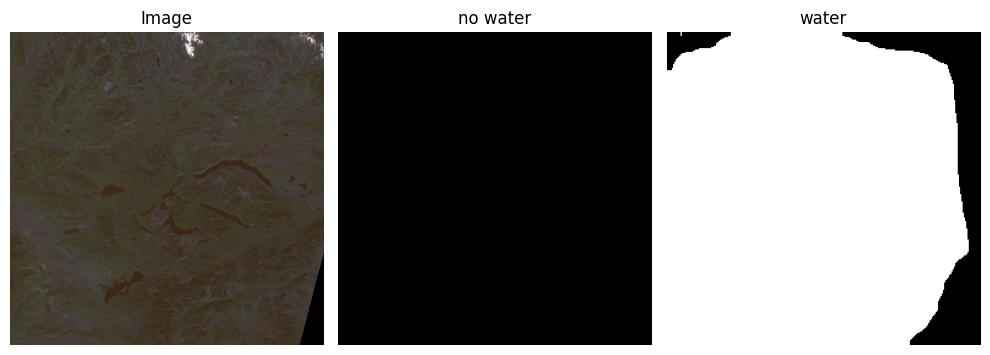

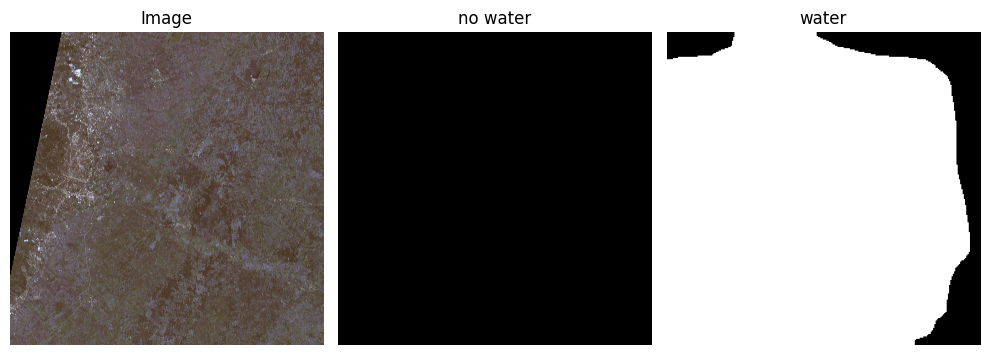

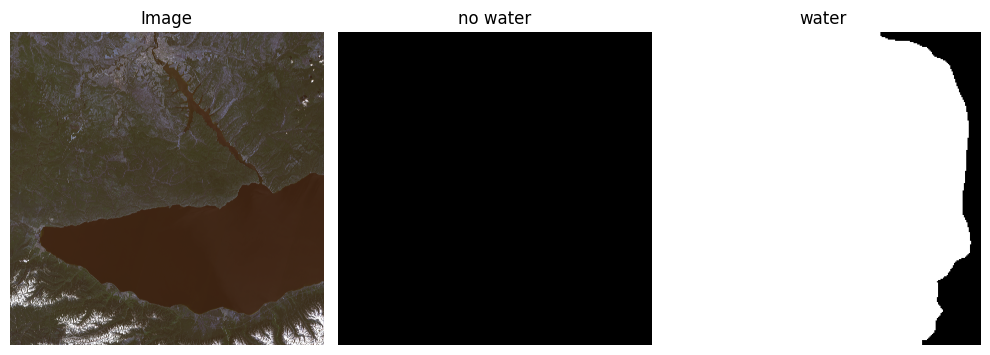

In [ ]:
model_path = "./data/S1S2-Water/S2/checkpoint.pth.tar"
labels = ["no water","water"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "./data/S1S2-Water/S2/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/S1S2-Water/S2/' + test_list[0])
image = image[:,:,0:3] / 3000
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/S1S2-Water/S2/' + test_list[1])
image = image[:,:,0:3] / 3000
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/S1S2-Water/S2/' + test_list[3])
image = image[:,:,0:3] / 3000
fig = model.predict_masks(image, labels, transform)